# Predicting NYC Airbnb Prices with Linear Regression
Name: Ashwin A | Batch: November Batch
Dataset: New York City Airbnb Open Data (AB_NYC_2019.csv), Kaggle : https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data

## Step 1: Load and Inspect the Data

In [18]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
df = pd.read_csv("AB_NYC_2019.csv")
df.shape

(48895, 16)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [20]:
print(df.select_dtypes(include="number").columns.tolist())
print(df.select_dtypes(include="object").columns.tolist())

['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


Numerical and categorical columns are listed above.

In [21]:
pd.DataFrame({"missing": df.isnull().sum(), "percent": (df.isnull().sum() / len(df) * 100).round(2)})

,missing,percent
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


## Step 2: Data Cleaning and Missing Values
last_review is a date column with many missing values, so it was dropped. Missing reviews_per_month means the listing has zero reviews, so these were filled with 0.

In [22]:
df = df.drop(columns=["last_review"])
print(df[df["reviews_per_month"].isnull()]["number_of_reviews"].describe())
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

count    10052.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: number_of_reviews, dtype: float64


Identifier columns (id, name, host_id, host_name) do not help the model, so they were dropped.

In [23]:
df = df.drop(columns=["id", "name", "host_id", "host_name"])
df.shape

(48895, 11)

## Step 3: Outliers
Box plots show extreme prices and very long minimum stays.

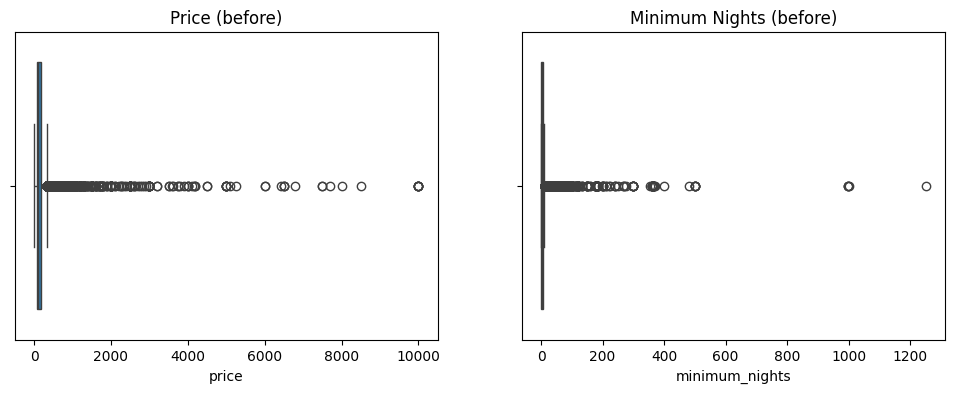

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(x=df["price"], ax=ax[0]); ax[0].set_title("Price (before)")
sns.boxplot(x=df["minimum_nights"], ax=ax[1]); ax[1].set_title("Minimum Nights (before)")
plt.show()

Listings above the 95th percentile of price and with minimum stays of 365 nights or more were removed, so the model focuses on typical listings.

In [25]:
rows_before = len(df)
price_cap = df["price"].quantile(0.95)
df = df[(df["price"] > 0) & (df["price"] <= price_cap) & (df["minimum_nights"] < 365)]
print(price_cap, rows_before, len(df))

355.0 48895 46406


Price and minimum nights after removing outliers.

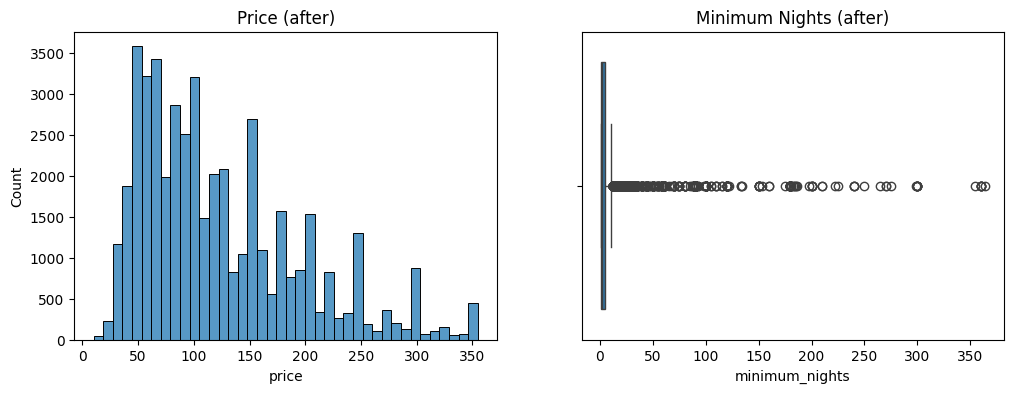

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df["price"], bins=40, ax=ax[0]); ax[0].set_title("Price (after)")
sns.boxplot(x=df["minimum_nights"], ax=ax[1]); ax[1].set_title("Minimum Nights (after)")
plt.show()

## Step 4: Feature Selection and Encoding
The neighbourhood column has 200+ values. Keeping it would add 200+ columns (curse of dimensionality), so it was dropped. neighbourhood_group and room_type were one-hot encoded with drop_first=True to avoid the dummy variable trap.

In [27]:
df = df.drop(columns=["neighbourhood"])
df = pd.get_dummies(df, columns=["neighbourhood_group", "room_type"], drop_first=True, dtype=int)
df.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


## Step 5: Features, Target and Train/Test Split
X holds the features and y is the price. Data was split 80% training and 20% testing with random_state=42.

In [28]:
X = df.drop(columns=["price"])
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(37124, 13) (9282, 13)


## Step 6: Model Training and Evaluation

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [30]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("R2:", round(r2, 3), "| MAE:", round(mae, 2), "| MSE:", round(mse, 2), "| RMSE:", round(rmse, 2))

R2: 0.47 | MAE: 38.14 | MSE: 2717.1 | RMSE: 52.13


## Step 7: Residual Analysis
Actual vs predicted prices. The red line shows a perfect prediction.

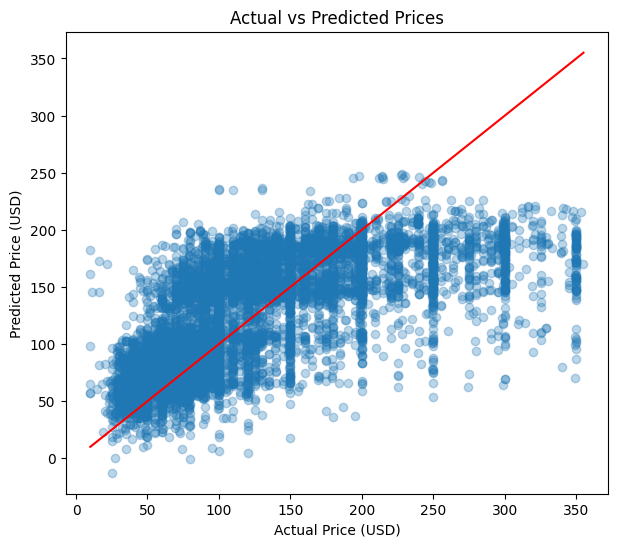

In [31]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.title("Actual vs Predicted Prices"); plt.xlabel("Actual Price (USD)"); plt.ylabel("Predicted Price (USD)")
plt.show()

Residual plot: errors against predicted prices.

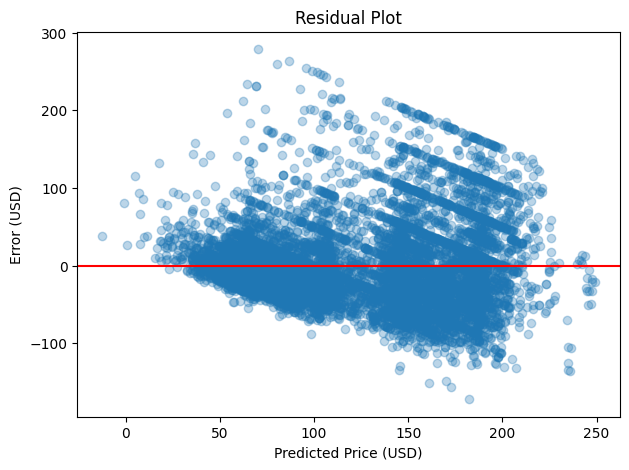

In [32]:
residuals = y_test - y_pred
plt.figure(figsize=(7,5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color="red")
plt.title("Residual Plot"); plt.xlabel("Predicted Price (USD)"); plt.ylabel("Error (USD)")
plt.show()

Distribution of errors.

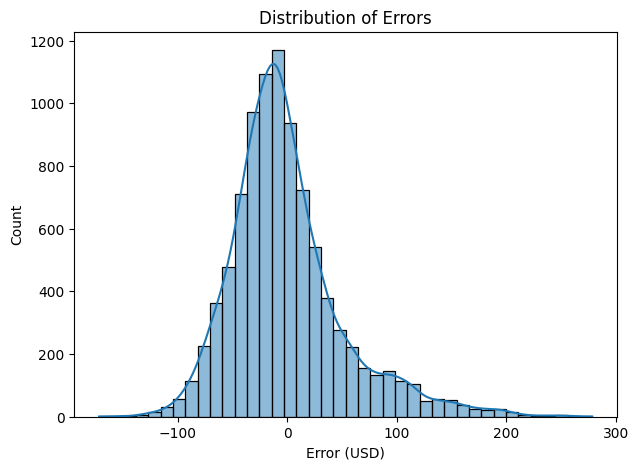

In [33]:
plt.figure(figsize=(7,5))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Distribution of Errors"); plt.xlabel("Error (USD)")
plt.show()

Comparing the error on cheaper and more expensive listings (split at the median price).

In [34]:
cheap = y_test <= y_test.median()
print("MAE cheap:", mean_absolute_error(y_test[cheap], y_pred[cheap]))
print("MAE expensive:", mean_absolute_error(y_test[~cheap], y_pred[~cheap]))

MAE cheap: 29.475388186952454
MAE expensive: 47.578123632460766


Final R2: 0.47. MAE: $38.14.
Answer: The model performs better on cheap listings (MAE $29.48) than on expensive ones (MAE $47.58). Expensive listings vary more in price, and the model only uses basic features like location and room type. It cannot see things like view, size or furnishing, which drive high prices.